# Install dan Import Library

In [ ]:
!pip install tensorflow

In [ ]:
!pip install openpyxl

In [ ]:
!pip install pydot graphviz

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.metrics import f1_score, confusion_matrix
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import plot_model

# Load Data

In [ ]:
from google.colab import files
upload = files.upload() #upload file data

Saving Data.csv to Data.csv


In [ ]:
data = pd.read_csv("Data.csv")
df = pd.DataFrame(data)
df

,Age,Glucose,Blood Pressure,BMI,Oxygen Saturation,LengthOfStay,Cholesterol,Triglycerides,HbA1c,Physical Activity,Diet Score,Stress Level,Sleep Hours,Medical Condition
0,46.0,137.04,135.27,28.90,96.04,6,231.88,210.56,7.61,-0.20,3.54,5.07,6.05,Diabetes
1,22.0,71.58,113.27,26.29,97.54,2,165.57,129.41,4.91,8.12,5.90,5.87,7.72,Healthy
2,50.0,95.24,NaN,22.53,90.31,2,214.94,165.35,5.60,5.01,4.65,3.09,4.82,Asthma
3,57.0,NaN,130.53,38.47,96.60,5,197.71,182.13,6.92,3.16,3.37,3.01,5.33,Obesity
4,66.0,95.15,178.17,31.12,94.90,4,259.53,115.85,5.98,3.56,3.40,6.38,6.64,Hypertension
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,54.0,86.35,127.68,28.30,94.36,1,218.60,152.82,4.85,9.15,10.35,3.65,8.71,Healthy
29996,41.0,89.24,154.37,24.93,96.07,4,198.30,176.81,5.36,3.34,3.40,6.72,2.81,Asthma
29997,83.0,NaN,170.11,30.55,97.83,3,210.13,168.76,5.05,4.53,4.50,4.31,3.61,NaN
29998,41.0,242.87,152.97,23.57,99.17,3,208.86,224.21,7.59,3.16,2.59,7.10,5.80,Diabetes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                25500 non-null  float64
 1   Glucose            25500 non-null  float64
 2   Blood Pressure     25500 non-null  float64
 3   BMI                30000 non-null  float64
 4   Oxygen Saturation  30000 non-null  float64
 5   LengthOfStay       30000 non-null  int64  
 6   Cholesterol        30000 non-null  float64
 7   Triglycerides      30000 non-null  float64
 8   HbA1c              30000 non-null  float64
 9   Physical Activity  30000 non-null  float64
 10  Diet Score         30000 non-null  float64
 11  Stress Level       30000 non-null  float64
 12  Sleep Hours        30000 non-null  float64
 13  Medical Condition  25500 non-null  object 
dtypes: float64(12), int64(1), object(1)
memory usage: 3.2+ MB


In [ ]:
print(df.isnull().sum())

Age                  4500
Glucose              4500
Blood Pressure       4500
BMI                     0
Oxygen Saturation       0
LengthOfStay            0
Cholesterol             0
Triglycerides           0
HbA1c                   0
Physical Activity       0
Diet Score              0
Stress Level            0
Sleep Hours             0
Medical Condition    4500
dtype: int64


In [ ]:
df = df.dropna(subset=['Medical Condition'])

In [ ]:
print(df.isnull().sum())

Age                  3821
Glucose              3788
Blood Pressure       3800
BMI                     0
Oxygen Saturation       0
LengthOfStay            0
Cholesterol             0
Triglycerides           0
HbA1c                   0
Physical Activity       0
Diet Score              0
Stress Level            0
Sleep Hours             0
Medical Condition       0
dtype: int64


In [ ]:
df["Age"].fillna(df["Age"].mean(), inplace=True)
df["Blood Pressure"].fillna(df["Blood Pressure"].mean(), inplace=True)
df["Glucose"].fillna(df["Glucose"].median(), inplace=True)

/tmp/ipython-input-3497497171.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Age"].fillna(df["Age"].mean(), inplace=True)
/tmp/ipython-input-3497497171.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Age"].fillna(df["Age"].mean(), inplace=True)
/tmp/ipython-input-3497497171.py:2: FutureWarning: A value is trying to be set on a

In [ ]:
print(df.isnull().sum())

Age                  0
Glucose              0
Blood Pressure       0
BMI                  0
Oxygen Saturation    0
LengthOfStay         0
Cholesterol          0
Triglycerides        0
HbA1c                0
Physical Activity    0
Diet Score           0
Stress Level         0
Sleep Hours          0
Medical Condition    0
dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25500 entries, 0 to 29999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                25500 non-null  float64
 1   Glucose            25500 non-null  float64
 2   Blood Pressure     25500 non-null  float64
 3   BMI                25500 non-null  float64
 4   Oxygen Saturation  25500 non-null  float64
 5   LengthOfStay       25500 non-null  int64  
 6   Cholesterol        25500 non-null  float64
 7   Triglycerides      25500 non-null  float64
 8   HbA1c              25500 non-null  float64
 9   Physical Activity  25500 non-null  float64
 10  Diet Score         25500 non-null  float64
 11  Stress Level       25500 non-null  float64
 12  Sleep Hours        25500 non-null  float64
 13  Medical Condition  25500 non-null  object 
dtypes: float64(12), int64(1), object(1)
memory usage: 2.9+ MB


In [ ]:
df.describe()

,Age,Glucose,Blood Pressure,BMI,Oxygen Saturation,LengthOfStay,Cholesterol,Triglycerides,HbA1c,Physical Activity,Diet Score,Stress Level,Sleep Hours
count,25500.000000,25500.000000,25500.000000,25500.000000,25500.000000,25500.00000,25500.000000,25500.000000,25500.000000,25500.000000,25500.000000,25500.000000,25500.000000
mean,54.642742,121.638633,140.447559,28.474939,94.950878,4.40549,213.072891,176.910747,6.292121,3.807093,4.035195,5.921881,6.231123
std,14.718707,38.549153,19.484785,5.727344,3.742507,2.74404,33.616404,48.802188,1.318946,2.011850,1.821913,2.222386,1.188446
min,10.000000,20.320000,74.240000,7.670000,67.510000,1.00000,95.730000,-22.480000,3.280000,-3.680000,-1.750000,-2.070000,1.590000
25%,47.000000,98.780000,127.640000,24.590000,92.990000,3.00000,189.410000,141.407500,5.330000,2.360000,2.780000,4.380000,5.420000
50%,54.642742,110.510000,140.447559,28.050000,95.300000,4.00000,211.760000,173.540000,5.970000,3.590000,3.790000,5.900000,6.230000
75%,64.000000,128.870000,150.780000,31.830000,97.380000,5.00000,235.370000,208.422500,6.910000,5.080000,5.030000,7.442500,7.050000
max,89.000000,318.510000,226.380000,56.850000,110.070000,19.00000,355.270000,421.510000,12.360000,12.410000,12.060000,15.450000,10.350000


In [ ]:
df

,Age,Glucose,Blood Pressure,BMI,Oxygen Saturation,LengthOfStay,Cholesterol,Triglycerides,HbA1c,Physical Activity,Diet Score,Stress Level,Sleep Hours,Medical Condition
0,46.0,137.04,135.270000,28.90,96.04,6,231.88,210.56,7.61,-0.20,3.54,5.07,6.05,Diabetes
1,22.0,71.58,113.270000,26.29,97.54,2,165.57,129.41,4.91,8.12,5.90,5.87,7.72,Healthy
2,50.0,95.24,140.447559,22.53,90.31,2,214.94,165.35,5.60,5.01,4.65,3.09,4.82,Asthma
3,57.0,110.51,130.530000,38.47,96.60,5,197.71,182.13,6.92,3.16,3.37,3.01,5.33,Obesity
4,66.0,95.15,178.170000,31.12,94.90,4,259.53,115.85,5.98,3.56,3.40,6.38,6.64,Hypertension
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29994,76.0,97.17,138.920000,25.65,93.99,3,235.65,238.26,6.43,3.14,3.46,6.66,6.10,Hypertension
29995,54.0,86.35,127.680000,28.30,94.36,1,218.60,152.82,4.85,9.15,10.35,3.65,8.71,Healthy
29996,41.0,89.24,154.370000,24.93,96.07,4,198.30,176.81,5.36,3.34,3.40,6.72,2.81,Asthma
29998,41.0,242.87,152.970000,23.57,99.17,3,208.86,224.21,7.59,3.16,2.59,7.10,5.80,Diabetes


In [ ]:
df.shape

(25500, 14)

In [ ]:
df.loc[:, 'Medical Condition'] = df['Medical Condition'].astype('category')
X = df.drop(columns=['Medical Condition'])
y = df['Medical Condition']

f_stats, f_p = f_classif(X, y)

anova_results = pd.DataFrame({
    'Feature': X.columns,
    'F_Statistic': f_stats,
    'p_value': f_p
}).sort_values(by='p_value')

print(anova_results)

              Feature  F_Statistic  p_value
0                 Age  2483.059502      0.0
1             Glucose  4932.501042      0.0
2      Blood Pressure  2353.455070      0.0
3                 BMI  2083.802805      0.0
4   Oxygen Saturation  1095.785146      0.0
5        LengthOfStay  8932.438095      0.0
6         Cholesterol  1179.367622      0.0
7       Triglycerides   927.539120      0.0
8               HbA1c  6413.939202      0.0
9   Physical Activity  4331.114683      0.0
10         Diet Score  3755.053487      0.0
11       Stress Level  1313.199521      0.0
12        Sleep Hours  1219.994078      0.0


In [ ]:
#Distribusi Frekuensi Label
print("Arthritis:", (df['Medical Condition'] == 'Arthritis').sum())
print("Asthma:", (df['Medical Condition'] == 'Asthma').sum())
print("Cancer:", (df['Medical Condition'] == 'Cancer').sum())
print("Diabetes:", (df['Medical Condition'] == 'Diabetes').sum())
print("Healthy:", (df['Medical Condition'] == 'Healthy').sum())
print("Hypertension:", (df['Medical Condition'] == 'Hypertension').sum())
print("Obesity:", (df['Medical Condition'] == 'Obesity').sum())

Arthritis: 1796
Asthma: 2037
Cancer: 1234
Diabetes: 6417
Healthy: 3039
Hypertension: 7120
Obesity: 3857


<Axes: ylabel='count'>

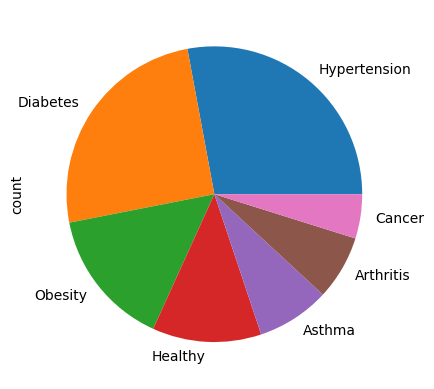

In [ ]:
df['Medical Condition'].value_counts().plot(kind='pie')

In [ ]:
df["Medical Condition"] = df["Medical Condition"].astype("category")
le = LabelEncoder()
df["Medical Condition"] = le.fit_transform(df["Medical Condition"])

/tmp/ipython-input-92860821.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Medical Condition"] = df["Medical Condition"].astype("category")
/tmp/ipython-input-92860821.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Medical Condition"] = le.fit_transform(df["Medical Condition"])


In [ ]:
le.classes_
mapping = {i: c for i, c in enumerate(le.classes_)}
print(mapping)

{0: 'Arthritis', 1: 'Asthma', 2: 'Cancer', 3: 'Diabetes', 4: 'Healthy', 5: 'Hypertension', 6: 'Obesity'}


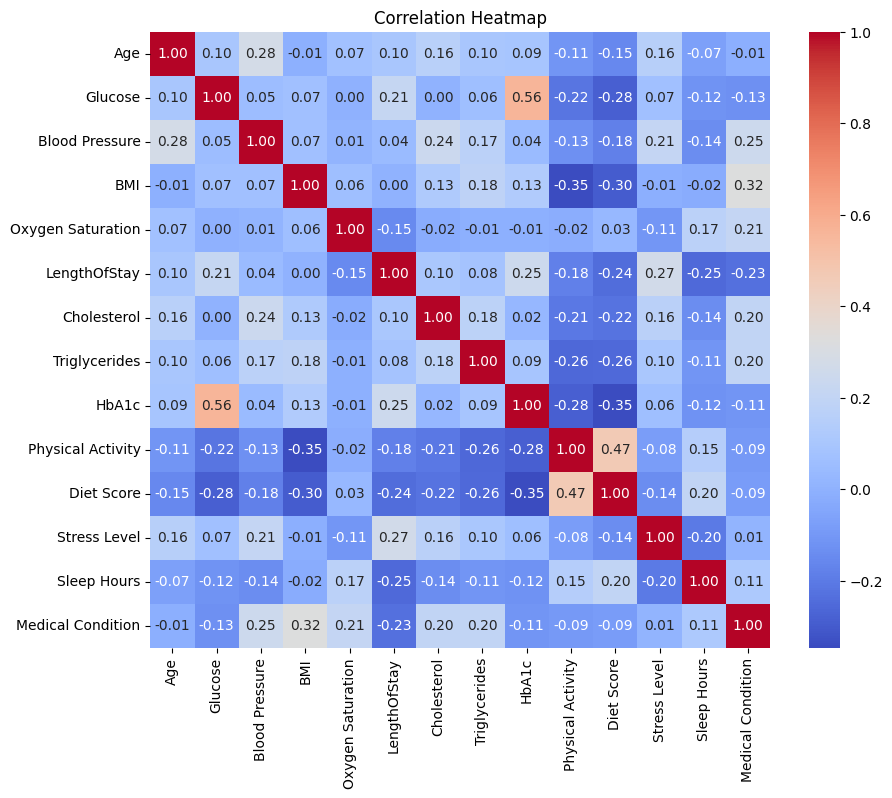

In [ ]:
df_corr = df.copy()
corr_matrix = df_corr.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
X = df.drop(columns=['Medical Condition'])
y = df['Medical Condition']

In [ ]:
#Pengecekan Outlier
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR)))

print("Jumlah Outlier Masing-Masing Variabel:")
print(outliers.sum())

Jumlah Outlier Masing-Masing Variabel:
Age                   623
Glucose              3105
Blood Pressure        660
BMI                   462
Oxygen Saturation     772
LengthOfStay         1041
Cholesterol           157
Triglycerides         254
HbA1c                 912
Physical Activity     216
Diet Score            577
Stress Level          123
Sleep Hours           119
dtype: int64


In [ ]:
y = y.astype(int)  # pastikan target berupa 0 dan 1, bukan kategori

In [ ]:
#Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size = 0.2,
                                                    random_state = 22020,
                                                    stratify = y)

In [ ]:
scaler = RobustScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index)

In [ ]:
# Scaling
scaler = RobustScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

with pd.ExcelWriter("Data_Scaled_RobustScaler.xlsx", engine="openpyxl") as writer:
    X_train_scaled.to_excel(writer, sheet_name="X_train_scaled")
    X_test_scaled.to_excel(writer, sheet_name="X_test_scaled")


# ANN

In [ ]:
import itertools

layer1_units = [18, 20, 22]
layer2_units = [10, 12, 14]

param_grid = list(itertools.product(layer1_units, layer2_units))

In [ ]:
def build_model(n1, n2):
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(n1, activation='relu'),
        Dense(n2, activation='relu'),
        Dense(7, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
results = []

for n1, n2 in param_grid:
    print(f"Training model: Layer1={n1}, Layer2={n2}")

    model = build_model(n1, n2)

    model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=50,
        batch_size=16,
        verbose=0
    )

    # Evaluasi
    y_prob = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    f1 = f1_score(y_test, y_pred, average='macro')

    results.append({
        'Layer1': n1,
        'Layer2': n2,
        'F1_macro': f1
    })

Training model: Layer1=18, Layer2=10
Training model: Layer1=18, Layer2=12
Training model: Layer1=18, Layer2=14
Training model: Layer1=20, Layer2=10
Training model: Layer1=20, Layer2=12
Training model: Layer1=20, Layer2=14
Training model: Layer1=22, Layer2=10
Training model: Layer1=22, Layer2=12
Training model: Layer1=22, Layer2=14


In [ ]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='F1_macro', ascending=False)

print(results_df)

   Layer1  Layer2  F1_macro
8      22      14  0.863044
3      20      10  0.861746
7      22      12  0.861065
4      20      12  0.858427
0      18      10  0.858214
5      20      14  0.853097
2      18      14  0.850983
1      18      12  0.850164
6      22      10  0.849251


In [ ]:
best_model = results_df.iloc[0]
print(best_model)

Layer1      22.000000
Layer2      14.000000
F1_macro     0.863044
Name: 8, dtype: float64


In [ ]:
#Membangun Model
model = Sequential([
                Input(shape=(X_train.shape[1],)),

                Dense(22, activation='relu'),

                Dense(14, activation='relu'),

                Dense(7, activation='softmax')
                ])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 22)             │           308 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │           322 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 735 (2.87 KB)

 Trainable params: 735 (2.87 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Training Model
history = model.fit(X_train, y_train,
          validation_split=0.2,
          epochs=50,
          batch_size=16,
          verbose=1)

Epoch 1/50
1020/1020 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3922 - loss: 13.3909 - val_accuracy: 0.5600 - val_loss: 1.3234
Epoch 2/50
1020/1020 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5696 - loss: 1.2406 - val_accuracy: 0.6632 - val_loss: 1.0575
Epoch 3/50
1020/1020 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6589 - loss: 1.0070 - val_accuracy: 0.7179 - val_loss: 0.8300
Epoch 4/50
1020/1020 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7040 - loss: 0.8344 - val_accuracy: 0.7392 - val_loss: 0.7343
Epoch 5/50
1020/1020 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7290 - loss: 0.7567 - val_accuracy: 0.7623 - val_loss: 0.6737
Epoch 6/50
1020/1020 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7656 - loss: 0.6532 - val_accuracy: 0.7821 - val_loss: 0.5961
Epoch 7/50
1020/1020 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7889 - loss: 0.5863 - val_accuracy: 0.8037 - val_loss: 0.5304
Epoch 8/50
1020/1020 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8086 - loss: 0.5233 -

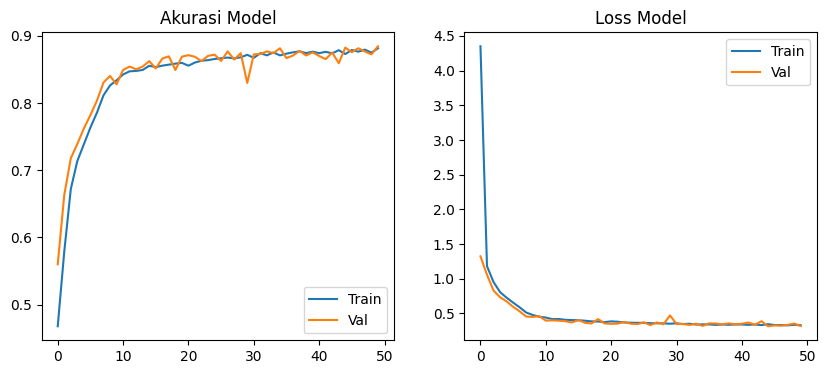

In [ ]:
#Plot Akurasi dan Loss Model
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Akurasi Model')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss Model')
plt.legend()
plt.show()

In [ ]:
#Evaluasi Model pada Data Training
y_prob = model.predict(X_train)
y_pred = np.argmax(y_prob, axis=1)
f1_macro = f1_score(y_train, y_pred, average='macro')
print("F1-score (Macro):", f1_macro)

638/638 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
F1-score (Macro): 0.8702345954504767


In [ ]:
#Evaluasi Model pada Data Testing
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
f1_macro = f1_score(y_test, y_pred, average='macro')
print("F1-score (Macro):", f1_macro)

160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
F1-score (Macro): 0.8648391580833026


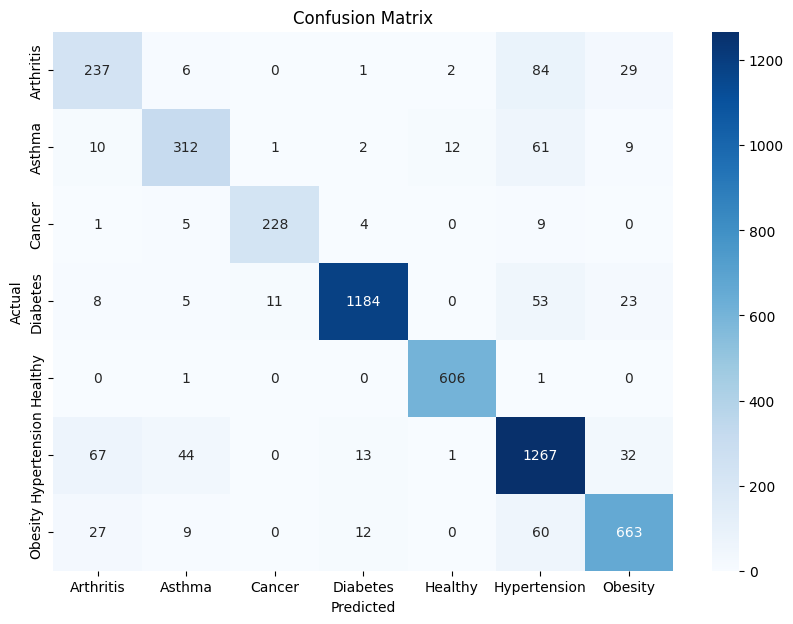

In [ ]:
#Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
class_names = le.classes_

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
def draw_ann_from_model(model):
    import matplotlib.pyplot as plt
    import networkx as nx
    layer_sizes = []
    for layer in model.layers:
        if hasattr(layer, 'units'):
            layer_sizes.append(layer.units)

    # Tambahkan input layer secara manual
    input_shape = model.input_shape[1]
    layer_sizes = [input_shape] + layer_sizes
    G = nx.DiGraph()
    pos = {}
    labels = {}
    layer_colors = ['lightgreen'] + ['skyblue'] * (len(layer_sizes) - 2) + ['salmon']
    for i, layer_size in enumerate(layer_sizes):
        for j in range(layer_size):
            node = f"L{i}_N{j}"
            pos[node] = (i, -j)
            G.add_node(node)
            labels[node] = f"{j+1}"
    for i in range(len(layer_sizes) - 1):
        for j in range(layer_sizes[i]):
            for k in range(layer_sizes[i+1]):
                G.add_edge(f"L{i}_N{j}", f"L{i+1}_N{k}")
    plt.figure(figsize=(12, 6))
    for i, layer_size in enumerate(layer_sizes):
        nodes = [f"L{i}_N{j}" for j in range(layer_size)]
        nx.draw_networkx_nodes(G, pos, nodelist = nodes, node_color = layer_colors[i], node_size = 600)
    nx.draw_networkx_edges(G, pos, arrows = True)
    nx.draw_networkx_labels(G, pos, labels, font_size = 8)
    plt.title("Visualisasi Arsitektur ANN dari Model Keras")
    plt.axis('off')
    plt.show()

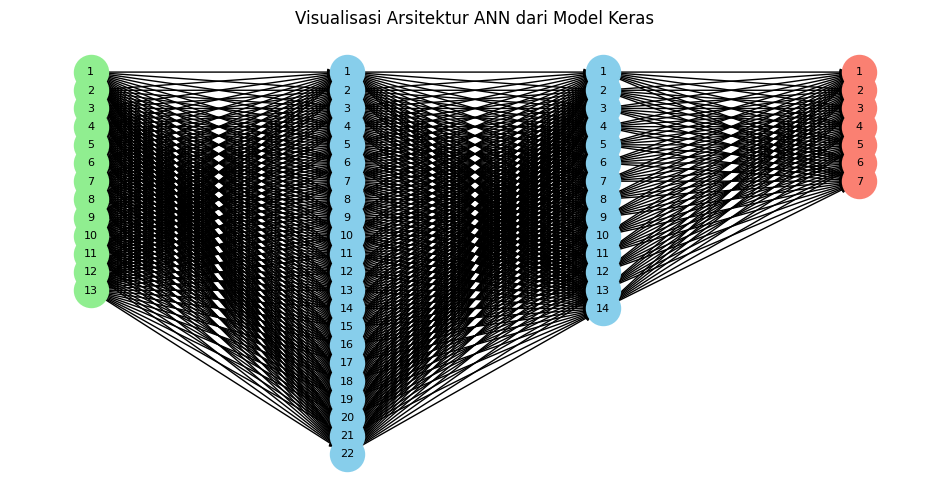

In [ ]:
draw_ann_from_model(model)

In [ ]:
for i, layer in enumerate(model.layers):
    weights = layer.get_weights()
    if weights:
        print(f"\nLayer {i+1}: {layer.name}")
        print("Bobot (weights):")
        print(weights[0])  # matriks bobot
        print("Bias:")
        print(weights[1])  # vektor bias


Layer 1: dense
Bobot (weights):
[[-0.03367449 -0.35142848 -0.226513   -0.7056033   0.2120233   0.02693679
   0.03836108  0.20609017  0.21782134 -0.25245756 -0.17203102 -0.24814759
  -0.02834749 -0.44504592  0.21947317 -0.3440886   0.3681229   0.23329812
   0.5097897  -0.16653845  0.45189473  0.14226606]
 [ 0.16276124  0.19168004 -0.20262194 -0.10992967 -0.24657048 -0.31319275
   0.1055626  -0.6410569   0.28913927  0.16553655  0.14403437 -0.2111624
  -0.23433195  0.14483866 -0.37949485  0.3394883   0.12908748  0.25393173
   0.37898958 -0.10055939 -0.31394076 -0.29856697]
 [ 0.16963959 -0.26620007  0.23913293  0.3275574   0.01226704 -0.2494448
  -0.00781233  0.13623643  0.28052774  0.19174328 -0.1610721   0.00879734
  -0.24682716  0.29546455  0.2270285   0.04798178 -0.12499014 -0.02238538
   0.07290597  0.36761096 -0.43067545  0.32462424]
 [ 0.13605228  0.46465576 -0.02698371 -0.13014504 -0.57743937 -0.11679698
   0.3813788   0.20280328  0.34468678 -0.18088894  0.07000721  0.36799905
  

In [ ]:
with pd.ExcelWriter("Bobot dan Bias.xlsx", engine="openpyxl") as writer:
    for i, layer in enumerate(model.layers):
        weights = layer.get_weights()

        if weights:
            W, b = weights

            # === DataFrame bobot ===
            df_weights = pd.DataFrame(
                W,
                columns=[f"Neuron_Out_{j+1}" for j in range(W.shape[1])],
                index=[f"Neuron_In_{k+1}" for k in range(W.shape[0])]
            )

            # === DataFrame bias ===
            df_bias = pd.DataFrame(
                b,
                columns=["Bias"],
                index=[f"Neuron_Out_{j+1}" for j in range(len(b))]
            )

            # === Simpan ke sheet Excel ===
            sheet_name = f"Layer_{i+1}_{layer.name}"

            df_weights.to_excel(writer, sheet_name=sheet_name, startrow=0)
            df_bias.to_excel(writer, sheet_name=sheet_name, startrow=W.shape[0] + 3)


In [ ]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

y_pred_label = le.inverse_transform(y_pred)
y_actual_label = le.inverse_transform(y_test)

for i in range(len(y_test)):
    peluang = np.round(y_prob[i], 3)
    print(
        f"Data ke-{i+1}: "
        f"Probabilitas = {peluang}")

Streaming output truncated to the last 5000 lines.
Data ke-101: Probabilitas = [0. 0. 0. 0. 1. 0. 0.]
Data ke-102: Probabilitas = [0. 0. 0. 1. 0. 0. 0.]
Data ke-103: Probabilitas = [0.069 0.    0.    0.    0.    0.931 0.   ]
Data ke-104: Probabilitas = [0. 0. 0. 0. 1. 0. 0.]
Data ke-105: Probabilitas = [0. 0. 0. 1. 0. 0. 0.]
Data ke-106: Probabilitas = [0.006 0.    0.    0.    0.    0.994 0.   ]
Data ke-107: Probabilitas = [0.    0.    0.    0.997 0.    0.003 0.   ]
Data ke-108: Probabilitas = [0.02  0.004 0.    0.007 0.    0.934 0.035]
Data ke-109: Probabilitas = [0.003 0.235 0.022 0.005 0.    0.736 0.   ]
Data ke-110: Probabilitas = [0. 0. 0. 1. 0. 0. 0.]
Data ke-111: Probabilitas = [0.082 0.01  0.001 0.001 0.    0.906 0.   ]
Data ke-112: Probabilitas = [0.001 0.002 0.    0.    0.    0.997 0.   ]
Data ke-113: Probabilitas = [0.006 0.039 0.    0.012 0.    0.003 0.941]
Data ke-114: Probabilitas = [0.002 0.006 0.    0.976 0.    0.011 0.005]
Data ke-115: Probabilitas = [0.002 0.929 0.   

# Prediksi Data Baru

In [ ]:
from sklearn.preprocessing import RobustScaler
import pandas as pd

# Fit scaler hanya pada data training
scaler = RobustScaler()
scaler.fit(X_train)

# Simpan median & IQR per fitur
stats_train = pd.DataFrame({
    "Feature": X_train.columns,
    "Median": scaler.center_,
    "IQR": scaler.scale_
})

stats_train

,Feature,Median,IQR
0,Age,54.642742,17.0000
1,Glucose,110.510000,29.9225
2,Blood Pressure,140.447559,22.9325
3,BMI,28.050000,7.2125
4,Oxygen Saturation,95.290000,4.4000
5,LengthOfStay,4.000000,2.0000
6,Cholesterol,211.615000,45.9525
7,Triglycerides,173.240000,67.0500
8,HbA1c,5.980000,1.5800
9,Physical Activity,3.600000,2.7200


In [ ]:
# Data Baru
data_baru = X_test.iloc[[0]]
data_baru

,Age,Glucose,Blood Pressure,BMI,Oxygen Saturation,LengthOfStay,Cholesterol,Triglycerides,HbA1c,Physical Activity,Diet Score,Stress Level,Sleep Hours
23386,75.0,140.55,158.03,18.22,95.69,5,194.19,174.8,6.1,7.33,4.45,9.66,7.09


In [ ]:
data_baru_scaled = pd.DataFrame(
    scaler.transform(data_baru),
    columns=X_train.columns
)

data_baru_scaled.transpose()

,0
Age,1.197486
Glucose,1.003927
Blood Pressure,0.766704
BMI,-1.362912
Oxygen Saturation,0.090909
LengthOfStay,0.500000
Cholesterol,-0.379196
Triglycerides,0.023266
HbA1c,0.075949
Physical Activity,1.371324


In [ ]:
# Bobot dan Bias
W1, b1 = model.layers[0].get_weights()  # (13, 22)
W2, b2 = model.layers[1].get_weights()  # (22, 14)
W3, b3 = model.layers[2].get_weights()  # (14, 7)

# Fungsi Aktivasi
def relu(z):
    return np.maximum(0, z)

def softmax(z):
    exp_z = np.exp(z - np.max(z))
    return exp_z / exp_z.sum()


In [ ]:
# Hidden Layer 1
z1 = np.dot(data_baru_scaled.values, W1) + b1
a1 = relu(z1)

z1, a1

(array([[ 1.46445557, -3.10298314,  0.18418726,  0.439539  ,  0.771637  ,
          2.4118971 , -1.69315967, -3.03043165, -4.27983172, -3.08630872,
         -0.35025751, -0.09561807, -0.82620573,  3.16054286, -1.58132202,
         -0.45845572,  0.66320967,  0.84637007,  7.04052007,  1.48730545,
         -2.49554795, -0.36851679]]),
 array([[1.46445557, 0.        , 0.18418726, 0.439539  , 0.771637  ,
         2.4118971 , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 3.16054286, 0.        ,
         0.        , 0.66320967, 0.84637007, 7.04052007, 1.48730545,
         0.        , 0.        ]]))

In [ ]:
# Hidden Layer 2
z2 = np.dot(a1, W2) + b2
a2 = relu(z2)

z2, a2

(array([[-1.44355808, -1.83653466, -5.43065013, -2.82953701,  4.57398134,
         -1.04714549, -4.99023899, -1.81256278, -2.70910967,  4.4158801 ,
         -2.2778885 , -1.16388985,  3.2678298 , -2.62166223]]),
 array([[0.        , 0.        , 0.        , 0.        , 4.57398134,
         0.        , 0.        , 0.        , 0.        , 4.4158801 ,
         0.        , 0.        , 3.2678298 , 0.        ]]))

In [ ]:
# Output Layer
z3 = np.dot(a2, W3) + b3
prob = softmax(z3[0])

z3, prob

(array([[ 0.95643059,  7.52344627,  0.44943977,  0.66875426, -0.83708271,
          0.57769934,  3.36771051]]),
 array([1.37817790e-03, 9.80220894e-01, 8.30083856e-04, 1.03363937e-03,
        2.29293821e-04, 9.43679224e-04, 1.53642317e-02]))

In [ ]:
# Probabilitas
y_baru_prob = model.predict(data_baru_scaled)

# Prediksi kelas
y_baru_class = np.argmax(y_baru_prob, axis=1)

# Tampilkan hasil
print("Probabilitas per kelas:")
for i, prob in enumerate(y_baru_prob[0]):
    print(f"{le.classes_[i]}: {prob:.3f}")

print("\nPrediksi kelas:", le.classes_[y_baru_class[0]])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Probabilitas per kelas:
Arthritis: 0.001
Asthma: 0.980
Cancer: 0.001
Diabetes: 0.001
Healthy: 0.000
Hypertension: 0.001
Obesity: 0.015

Prediksi kelas: Asthma


In [ ]:
df_input = data_baru_scaled.T
df_input.columns = ["Nilai_Scaled"]

df_hidden1 = pd.DataFrame({
    "z": z1.flatten(),
    "ReLU(z)": a1.flatten()
}, index=[f"Neuron_{i+1}" for i in range(22)])

df_hidden2 = pd.DataFrame({
    "z": z2.flatten(),
    "ReLU(z)": a2.flatten()
}, index=[f"Neuron_{i+1}" for i in range(14)])

df_output = pd.DataFrame({
    "z": z3.flatten(),
    "Probabilitas": prob
}, index=le.classes_)

with pd.ExcelWriter("Prediksi Manual.xlsx", engine="openpyxl") as writer:
    df_input.to_excel(writer, sheet_name="Input_Scaled")
    df_hidden1.to_excel(writer, sheet_name="Hidden_Layer_1")
    df_hidden2.to_excel(writer, sheet_name="Hidden_Layer_2")
    df_output.to_excel(writer, sheet_name="Output_Softmax")